# Notebook 2 — `2_preprocessing_map`

## Overview

**Purpose:** Process official BIG administrative boundaries, link regency and municipality geometries to BPS codes, calculate spatial centroids, and enrich the compiled BNPB flood data with spatial attributes.

This notebook uses the official BIG RBI50K geodatabase as the authoritative source for administrative boundaries in the journal version of the research.

## Data requirements

Download the following data before running the notebook. The `data/raw/` directory is empty in this repository because raw data are not redistributed in accordance with the providers' terms of use.

| Dataset | Source | Required files | Directory |
|---|---|---|---|
| Administrative boundaries | [BIG Geoportal](https://tanahair.indonesia.go.id/portal-web/unduh/) (login required) | BIG RBI50K administrative boundary geodatabase, `RBI50K_ADMINISTRASI_KABKOTA_20230907.gdb` | `data/raw/BIG/` |
| BPS master codes (Bridging Kode) | [BPS Bridging Kode](https://sig.bps.go.id/bridging-kode/index) | Same master files used in Notebook 1 | `data/raw/BPS/BPS_Master_Code/` |

## Input from Notebook 1

`data/processed/1_bencana_compiled_with_bps.xlsx`

## Workflow

| Step | Description |
|---|---|
| 1 | Define helper functions to normalise Kemendagri dot-separated codes into four-digit codes |
| 2 | Load the BIG geodatabase, process the geometries, and dissolve them into 514 regency and municipality polygons |
| 3 | Load the BPS master codes and establish the Kemendagri-to-BPS code mapping |
| 4 | Join administrative boundaries to BPS codes using `KDPKAB` and `kemendagri_kab_code`, with an expected match of 514 out of 514 units |
| 5 | Perform a name-based consistency check to detect potential code mismatches |
| 6 | Calculate regency and municipality representative points located within their polygons |
| 7 | Calculate province-level interior points from dissolved province geometries |
| 8 | Export administrative geometries and BPS codes to a GeoPackage |
| 9 | Export regency and province centroid coordinates |
| 10 | Enrich the compiled BNPB flood data with spatial attributes |
| 11 | Validate the final outputs |

## Outputs

| File | Description |
|---|---|
| `data/processed/2_Kab_Kota_with_BPS.gpkg` | Administrative geometries linked to BPS codes, used for dashboard choropleths |
| `data/processed/2_regency_centroids.xlsx` | Regency and province centroid coordinates for mapping |
| `data/processed/2_bencana_compiled_with_bps_shp.xlsx` | Compiled BNPB flood records enriched with spatial attributes |

## Administrative code matching

The BIG `KDPKAB` field matches the BPS master field `kemendagri_kab_code` after code-format normalisation. This enables a direct code-based join, with an expected match of all 514 regencies and municipalities.

Unlike the earlier workflow, this version does not require extensive name-matching procedures, Papua legacy-code remapping, or three-tier code-and-name matching. Downstream analyses continue to use `bps_kab_code` as the administrative identifier.

## Important note on geometry

The BIG RBI50K geodatabase uses WGS 84 coordinates with EGM2008 height information in a three-dimensional coordinate representation. The elevation coordinate is dropped to produce two-dimensional geometries in EPSG:4326.

For regency and municipality mapping, `representative_point()` is used instead of `centroid()`. A representative point is guaranteed to lie within its polygon, whereas a geometric centroid may fall outside the polygon, particularly for concave or archipelagic administrative areas.

## STEP 1 — Helper: Kemendagri dot-code → 4-digit

`dot_to_4` normalises both the BIG `KDPKAB` (e.g. `"72.01"`, `"11.10"`) and the
master `kemendagri_kab_code` (e.g. `"11.1"`) to a common 4-digit string
(`"7201"`, `"1110"`), so `.10` vs `.1` formatting never breaks the join.


In [2]:
import struct, re, warnings
import numpy as np
import pandas as pd
import geopandas as gpd
from shapely import force_2d
warnings.filterwarnings("ignore")

# ── Paths (EDIT to your local paths) ─────────────────────────────────────
GDB_PATH    = "../data/raw/BIG/RBI50K_ADMINISTRASI_KABKOTA_20230907.gdb"
MASTER_PATH = "../data/raw/BPS/BPS_Master_Code/master_code_full.xlsx"
BNPB_PATH   = "../data/processed/1_bencana_compiled_with_bps.xlsx"

# Output filenames (written to working directory)
OUT_GPKG     = "../data/processed/2_Kab_Kota_with_BPS.gpkg"
OUT_CENTROID = "../data/processed/2_regency_centroids.xlsx"
OUT_BNPB     = "../data/processed/2_bencana_compiled_with_bps_shp.xlsx"

BIG_LAYER = "ADMINISTRASI_AR_KABKOTA"   # AR = area polygons (LN = lines, ignore)


In [4]:
def dot_to_4(code):
    """'11.09'->'1109', '11.1'->'1110', '72.01'->'7201'. Idempotent on 4-digit."""
    code = str(code).strip()
    if "." in code:
        prov, kab = code.split(".", 1)
        kab = kab.strip()
        kab = kab + "0" if len(kab) == 1 else kab.zfill(2)
        return prov.zfill(2) + kab
    return code.zfill(4)

# sanity check
for s in ["11.10", "11.1", "72.01", "73.10", "73.1"]:
    print(f"  {s:>6} -> {dot_to_4(s)}")


   11.10 -> 1110
    11.1 -> 1110
   72.01 -> 7201
   73.10 -> 7310
    73.1 -> 7310


## STEP 2 — Load BIG geodatabase, clean, dissolve → 514

Three cleaning steps before the dissolve:
1. **Flatten CRS** — BIG ships WGS84 + EGM2008 height (3D); drop the Z so it is
   plain EPSG:4326.
2. **Drop non-regency rows** — water bodies (`KDPKAB` empty / name blank) and the
   malformed shared-boundary row whose `KDPKAB` contains `"/"`.
3. **Dissolve by `KDPKAB`** — merges multipart archipelagic regencies (e.g. one
   code spread over several island polygons) into one row each.

Result must be exactly **514**.


In [6]:
gdf = gpd.read_file(GDB_PATH, layer=BIG_LAYER)
print(f"Raw BIG rows: {len(gdf)}")

# 1. Flatten CRS 3D -> 2D
gdf = gdf.set_crs("EPSG:4326", allow_override=True)
gdf["geometry"] = gdf["geometry"].apply(lambda g: force_2d(g) if g is not None else g)

# 2. Drop water bodies (empty KDPKAB / blank name) + slash-code rows
gdf["KDPKAB"] = gdf["KDPKAB"].astype(str).str.strip()
mask_empty = (gdf["KDPKAB"] == "") | (gdf["KDPKAB"].str.lower() == "nan") | (gdf["WADMKK"].isna())
mask_slash = gdf["KDPKAB"].str.contains("/", na=False)
drop_mask  = mask_empty | mask_slash
print(f"Dropping {int(drop_mask.sum())} non-regency rows (water bodies + slash-codes)")
gdf = gdf.loc[~drop_mask].copy()

# 3. Dissolve multipart -> one polygon per regency
gdf = gdf.dissolve(by="KDPKAB", as_index=False, aggfunc="first")

# Normalise code
gdf["kode_4"] = gdf["KDPKAB"].apply(dot_to_4)

assert len(gdf) == 514, f"Expected 514 regencies, got {len(gdf)}"
print(f"After dissolve: {len(gdf)} regencies")
print(gdf[["KDPKAB", "kode_4", "WADMKK", "WADMPR"]].head().to_string(index=False))


Raw BIG rows: 548
Dropping 28 non-regency rows (water bodies + slash-codes)
After dissolve: 514 regencies
KDPKAB kode_4        WADMKK WADMPR
 11.01   1101  Aceh Selatan   Aceh
 11.02   1102 Aceh Tenggara   Aceh
 11.03   1103    Aceh Timur   Aceh
 11.04   1104   Aceh Tengah   Aceh
 11.05   1105    Aceh Barat   Aceh


## STEP 3 — Load BPS master

`master_code_full.xlsx` is the BPS↔Kemendagri bridging table. It maps
`kemendagri_kab_code` → `bps_kab_code`. Note the two codes differ per regency
(e.g. Aceh Selatan is Kemendagri 11.01 → BPS 1103); the join uses the Kemendagri
code, then carries the BPS code downstream.


In [8]:
master = pd.read_excel(MASTER_PATH)
if "no" in master.columns:
    master = master.drop(columns=["no"])
master.columns = master.columns.str.strip().str.lower().str.replace(" ", "_")

# Normalise codes (SAME dot_to_4 as gdf so they align)
master["kode_4"]        = master["kemendagri_kab_code"].apply(dot_to_4)
master["bps_kab_code"]  = pd.to_numeric(master["bps_kab_code"], errors="coerce").astype("Int64")
master["bps_prov_code"] = pd.to_numeric(master["bps_prov_code"], errors="coerce").astype("Int64")
master = master.dropna(subset=["kode_4", "bps_kab_code"]).copy()

print(f"Master records: {len(master)}")

# Alignment check (expect 514/514)
_b, _m = set(gdf["kode_4"]), set(master["kode_4"])
print(f"Code overlap gdf vs master: {len(_b & _m)}/514")
print(f"  in gdf not master: {sorted(_b - _m)}")
print(f"  in master not gdf: {sorted(_m - _b)}")


Master records: 514
Code overlap gdf vs master: 514/514
  in gdf not master: []
  in master not gdf: []


## STEP 4 — Join by code → retrieve `bps_kab_code`

A single merge on `kode_4` replaces the entire old name-matching pipeline
(province/regency dictionaries, Papua remap, 3-tier code+name matching). Expect
**514/514 matched, 0 unmatched**.


In [12]:
gdf = gdf.merge(
    master[["kode_4", "bps_kab_code", "bps_kab_name", "bps_prov_code",
            "bps_prov_name", "kemendagri_kab_code", "kemendagri_kab_name",
            "kemendagri_prov_code", "kemendagri_prov_name"]],  
    on="kode_4", how="left"
)
gdf["match_status"] = np.where(gdf["bps_kab_code"].notna(), "code_match", "unmatched")

n_unmatched = int((gdf["match_status"] == "unmatched").sum())
print(f"Join by code: {int((gdf['match_status']=='code_match').sum())}/514 matched, {n_unmatched} unmatched")
assert n_unmatched == 0, "Some regencies unmatched — check codes"

print(gdf[["KDPKAB", "WADMKK", "kode_4", "bps_kab_code", "bps_kab_name"]].head().to_string(index=False))


Join by code: 514/514 matched, 0 unmatched
KDPKAB        WADMKK kode_4  bps_kab_code       bps_kab_name
 11.01  Aceh Selatan   1101          1103  Kab. Aceh Selatan
 11.02 Aceh Tenggara   1102          1104 Kab. Aceh Tenggara
 11.03    Aceh Timur   1103          1105    Kab. Aceh Timur
 11.04   Aceh Tengah   1104          1106   Kab. Aceh Tengah
 11.05    Aceh Barat   1105          1107    Kab. Aceh Barat


## STEP 5 — Name sanity check (verify no swapped codes)

The join uses codes, but comparing the BIG name (`WADMKK`) with the BPS name
(`bps_kab_name`) confirms no code got mismatched. High similarity everywhere
(min ~0.91, differences only spelling/prefix) means the geometry attaches to the
correct regency.


In [14]:
import difflib
def _clean(x):
    return (str(x).upper().replace("KAB.", "").replace("KABUPATEN", "")
            .replace("KOTA", "").replace(".", "").strip())
def _sim(a, b):
    return difflib.SequenceMatcher(None, _clean(a), _clean(b)).ratio()

gdf["name_sim"] = gdf.apply(lambda r: _sim(r["WADMKK"], r["bps_kab_name"]), axis=1)
suspect = gdf[gdf["name_sim"] < 0.6]
print(f"Name-mismatch suspects (sim < 0.6): {len(suspect)}")
if len(suspect):
    print(suspect[["kode_4", "WADMKK", "bps_kab_name", "name_sim"]].to_string(index=False))
print(f"\nMin similarity: {gdf['name_sim'].min():.3f}  (higher = safer)")
print("10 lowest (for eyeballing):")
print(gdf.nsmallest(10, "name_sim")[["kode_4", "WADMKK", "bps_kab_name", "name_sim"]].to_string(index=False))


Name-mismatch suspects (sim < 0.6): 0

Min similarity: 0.909  (higher = safer)
10 lowest (for eyeballing):
kode_4               WADMKK             bps_kab_name  name_sim
  5302 Timor Tengah Selatan Kab Timor Tengah Selatan  0.909091
  1101         Aceh Selatan        Kab. Aceh Selatan  1.000000
  1102        Aceh Tenggara       Kab. Aceh Tenggara  1.000000
  1103           Aceh Timur          Kab. Aceh Timur  1.000000
  1104          Aceh Tengah         Kab. Aceh Tengah  1.000000
  1105           Aceh Barat          Kab. Aceh Barat  1.000000
  1106           Aceh Besar          Kab. Aceh Besar  1.000000
  1107                Pidie               Kab. Pidie  1.000000
  1108           Aceh Utara          Kab. Aceh Utara  1.000000
  1109             Simeulue            Kab. Simeulue  1.000000


## STEP 6 — Regency centroids (representative_point, on land)

`representative_point()` guarantees a point *inside* the polygon (unlike
`centroid`, which can fall in the sea for concave or archipelagic regencies).
Computed in a projected CRS, returned as lat/lon.


Sample centroids:
kode_4        WADMKK  centroid_lat  centroid_lon
  1101  Aceh Selatan      3.068769     97.468469
  1102 Aceh Tenggara      3.338577     97.745750
  1103    Aceh Timur      4.704162     97.642017
  1104   Aceh Tengah      4.565309     96.976907
  1105    Aceh Barat      4.429257     96.181552


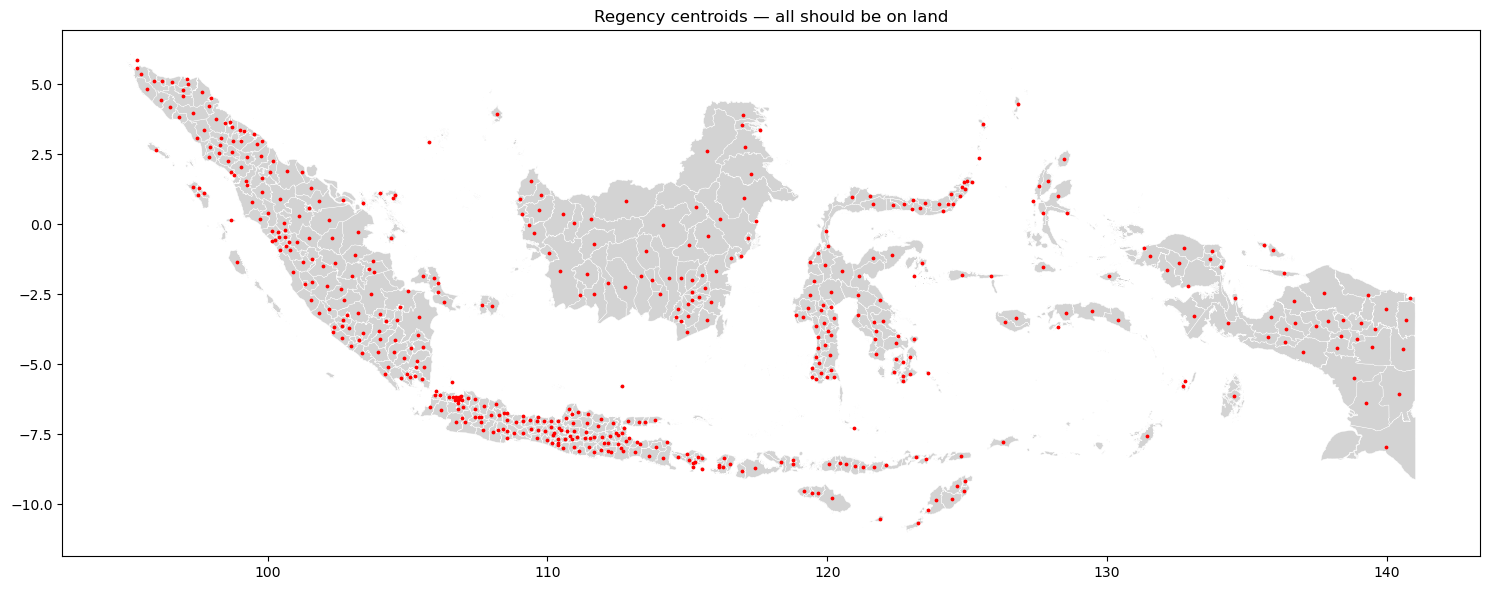

In [16]:
gdf_proj = gdf.to_crs("EPSG:32748")   # UTM 48S, covers most of Indonesia
rep_pt = gdf_proj.geometry.representative_point().to_crs("EPSG:4326")
gdf["centroid_lon"] = rep_pt.x.values
gdf["centroid_lat"] = rep_pt.y.values

print("Sample centroids:")
print(gdf[["kode_4", "WADMKK", "centroid_lat", "centroid_lon"]].head().to_string(index=False))

# Plot check: all points must be on land
import matplotlib.pyplot as plt
ax = gdf.plot(figsize=(15, 6), color="lightgray", edgecolor="white", linewidth=0.3)
pts = gpd.GeoSeries(gpd.points_from_xy(gdf.centroid_lon, gdf.centroid_lat), crs="EPSG:4326")
pts.plot(ax=ax, color="red", markersize=3)
ax.set_title("Regency centroids — all should be on land")
plt.tight_layout(); plt.show()


## STEP 7 — Province centroids (dissolve geometry, interior point)

Averaging regency centroids is unreliable (unweighted, can land in the sea for
archipelagic provinces). Instead dissolve the actual geometry by province and
take an interior point, keeping the marker on land.


In [18]:
_gp = gdf.dropna(subset=["bps_prov_code"]).copy()
_prov_geom = _gp.dissolve(by="bps_prov_code", as_index=False)
_prov_proj = _prov_geom.to_crs("EPSG:32748")
_prov_pt   = _prov_proj.geometry.representative_point().to_crs("EPSG:4326")

prov_centroids = pd.DataFrame({
    "bps_prov_code": _prov_geom["bps_prov_code"].values,
    "centroid_lat":  _prov_pt.y.values,
    "centroid_lon":  _prov_pt.x.values,
})
_meta = (gdf.groupby(["bps_prov_code", "bps_prov_name"])
         .agg(n_regencies=("bps_kab_code", "count")).reset_index())
prov_centroids = (prov_centroids.merge(_meta, on="bps_prov_code", how="left")
                  .sort_values("bps_prov_code"))
print(f"Province centroids: {len(prov_centroids)}")
print(prov_centroids.to_string(index=False))


Province centroids: 45
 bps_prov_code  centroid_lat  centroid_lon             bps_prov_name  n_regencies
            11      3.923466     97.176217                      Aceh           23
            12      2.269412     99.265904            Sumatera Utara           33
            13     -0.784505    100.874561            Sumatera Barat           19
            14      0.712585    101.590753                      Riau           12
            15     -1.749379    102.581451                     Jambi           11
            16     -3.275648    104.294627          Sumatera Selatan           17
            17     -3.606164    102.474492                  Bengkulu           10
            18     -4.833532    105.112277                   Lampung           15
            19     -2.899551    107.905490 Kepulauan Bangka Belitung            7
            21      3.930111    108.190174            Kepulauan Riau            7
            31     -6.230701    106.846215               Dki Jakarta       

## STEP 8 — Save GeoPackage (geometry + BPS codes)

`Kab_Kota_with_BPS.gpkg` is the geometry file consumed by the dashboard
choropleth. Helper/temp columns are dropped before writing.


In [20]:
export_gdf = gdf.drop(columns=[c for c in ["name_sim"] if c in gdf.columns]).copy()
export_gdf["kemendagri_kab_code_4"] = export_gdf["kode_4"]   # ← alias untuk nb12
export_gdf["bps_kab_code"] = pd.to_numeric(export_gdf["bps_kab_code"], errors="coerce").astype("Int64")  # ← int untuk nb7
export_gdf.to_file(OUT_GPKG, driver="GPKG")

print(f"Saved {OUT_GPKG}: {len(export_gdf)} regencies")
print("Columns:", export_gdf.columns.tolist())

Saved ../data/processed/2_Kab_Kota_with_BPS.gpkg: 514 regencies
Columns: ['KDPKAB', 'geometry', 'NAMOBJ', 'FCODE', 'REMARK', 'METADATA', 'SRS_ID', 'KDBBPS', 'KDCBPS', 'KDCPUM', 'KDEBPS', 'KDEPUM', 'KDPBPS', 'KDPPUM', 'LUASWH', 'TIPADM', 'WADMKC', 'WADMKD', 'WADMKK', 'WADMPR', 'WIADKC', 'WIADKK', 'WIADPR', 'WIADKD', 'SHAPE_Length', 'SHAPE_Area', 'kode_4', 'bps_kab_code', 'bps_kab_name', 'bps_prov_code', 'bps_prov_name', 'kemendagri_kab_code', 'kemendagri_kab_name', 'kemendagri_prov_code', 'kemendagri_prov_name', 'match_status', 'centroid_lon', 'centroid_lat', 'kemendagri_kab_code_4']


## STEP 9 — Save centroids (regency + province)

`2_regency_centroids.xlsx` with two sheets, consumed by the dashboard map
points and by rq1_analysis for spatial weights.


In [22]:
regency_out = gdf[[
    "bps_kab_code", "bps_kab_name", "bps_prov_code", "bps_prov_name",
    "kemendagri_kab_code", "kode_4", "WADMKK", "WADMPR",
    "centroid_lat", "centroid_lon", "match_status",
]].copy()
province_out = prov_centroids[[
    "bps_prov_code", "bps_prov_name", "centroid_lat", "centroid_lon", "n_regencies",
]].copy()

with pd.ExcelWriter(OUT_CENTROID, engine="openpyxl") as w:
    regency_out.to_excel(w, sheet_name="Regency Centroids", index=False)
    province_out.to_excel(w, sheet_name="Province Centroids", index=False)
print(f"Saved {OUT_CENTROID}")
print(f"  Regency Centroids : {len(regency_out)} rows")
print(f"  Province Centroids: {len(province_out)} rows")


Saved ../data/processed/2_regency_centroids.xlsx
  Regency Centroids : 514 rows
  Province Centroids: 45 rows


## STEP 10 — Enrich BNPB combined data with SHP attributes

Join key is `bps_kab_code` (BNPB already carries it). Adds the BIG/Kemendagri
identifiers so downstream notebooks can link flood events to geometry.
`2_bencana_compiled_with_bps_shp.xlsx` is consumed by nb12 + dashboard.


In [24]:
bnpb = pd.read_excel(BNPB_PATH, sheet_name="Combined")
bnpb["bps_kab_code"] = pd.to_numeric(bnpb["bps_kab_code"], errors="coerce").astype("Int64")
print(f"BNPB combined rows: {len(bnpb)}")

# One row per bps_kab_code from the geometry side
shp_join = (gdf[["bps_kab_code", "KDPKAB", "kode_4"]]
            .drop_duplicates(subset=["bps_kab_code"]).copy())
shp_join["bps_kab_code"] = pd.to_numeric(shp_join["bps_kab_code"], errors="coerce").astype("Int64")

bnpb_enriched = bnpb.merge(shp_join, on="bps_kab_code", how="left")
n_matched = int(bnpb_enriched["KDPKAB"].notna().sum())
n_missing = int(bnpb_enriched["KDPKAB"].isna().sum())
print(f"Matched to SHP geometry: {n_matched:,} ({n_matched/len(bnpb_enriched)*100:.1f}%)")
print(f"No SHP match           : {n_missing:,}")
if n_missing:
    miss = (bnpb_enriched[bnpb_enriched["KDPKAB"].isna()]
            [["bps_kab_code", "bps_kab_name", "bps_prov_name"]]
            .drop_duplicates().sort_values("bps_kab_code"))
    print(f"Unmatched codes ({miss['bps_kab_code'].nunique()} unique):")
    print(miss.to_string(index=False))

with pd.ExcelWriter(OUT_BNPB, engine="openpyxl") as w:
    bnpb_enriched.to_excel(w, sheet_name="Combined", index=False)
    pd.DataFrame([
        ["BNPB total rows", len(bnpb_enriched)],
        ["Matched to SHP",  n_matched],
        ["No SHP match",    n_missing],
        ["Unique bps_kab_code", bnpb_enriched["bps_kab_code"].nunique()],
        ["Geometry source", "BIG RBI50K ADMINISTRASI_KABKOTA 20230907"],
    ], columns=["Item", "Value"]).to_excel(w, sheet_name="Join Summary", index=False)
print(f"\nSaved {OUT_BNPB}")


BNPB combined rows: 13030
Matched to SHP geometry: 13,030 (100.0%)
No SHP match           : 0

Saved ../data/processed/2_bencana_compiled_with_bps_shp.xlsx


## STEP 11 — Final export check

Confirm the three downstream artefacts exist.


In [26]:
import os
for fname, role in [
    (OUT_GPKG,     "geometry + BPS codes (dashboard choropleth)"),
    (OUT_CENTROID, "regency + province centroids (map points)"),
    (OUT_BNPB,     "BNPB events + SHP attributes (nb12 + dashboard)"),
]:
    ok = os.path.exists(fname)
    size = f"{os.path.getsize(fname)/1024:,.0f} KB" if ok else "MISSING"
    print(f"  {'OK ' if ok else 'XX '}{fname:<42} {size}")
    print(f"      {role}")
print("\nGeometry source: BIG RBI50K (authoritative) — cite for the journal manuscript.")


  OK ../data/processed/2_Kab_Kota_with_BPS.gpkg 213,660 KB
      geometry + BPS codes (dashboard choropleth)
  OK ../data/processed/2_regency_centroids.xlsx 48 KB
      regency + province centroids (map points)
  OK ../data/processed/2_bencana_compiled_with_bps_shp.xlsx 2,641 KB
      BNPB events + SHP attributes (nb12 + dashboard)

Geometry source: BIG RBI50K (authoritative) — cite for the journal manuscript.
